# Delta wave detection

Run this notebook from top to bottom in a Python kernel with `neuro_py` installed.
The synthetic example runs without external data and demonstrates detection,
waveform plots, interval restrictions, and a CellExplorer MAT-file round trip.
The optional session section uses HMC1/day8 after you set `RUN_SESSION = True`.

The detector returns a pandas DataFrame. Its default save name is
**`basename.deltaWaves.events.mat`**, and `event_name` allows custom names.
Existing files are always protected. Session saving is disabled in this notebook
until you explicitly enable it; the export demonstration uses a temporary folder.

In [1]:
%matplotlib inline

from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from neuro_py.detectors import detect_delta_waves, save_delta_wave_events
from neuro_py.io import loading
from neuro_py.io.matlab import load_mat

## 1. Create a reproducible single-channel recording

The sample clock is in seconds, the sampling rate is in Hz, and LFP shape is
`(n_samples,)`. Three isolated positive waves are embedded in low-amplitude noise.

In [2]:
fs = 250.0
sample_times = np.arange(0, 30, 1 / fs)
rng = np.random.default_rng(42)
trace = rng.normal(0, 0.1, sample_times.size)
expected_peaks = np.array([5.0, 15.0, 25.0])
for peak in expected_peaks:
    relative_time = sample_times - peak
    trace += (
        8
        * np.cos(2 * np.pi * 2.5 * relative_time)
        * np.exp(-((relative_time / 0.15) ** 2))
    )

## 2. Detect waves and inspect the DataFrame

For array input, disable session-based NREM/EMG restrictions explicitly and set
`save_mat=False`. Artifact rejection is disabled for this known-clean simulation:
its deliberately rare, large waves exceed the raw-amplitude artifact threshold.
The real-session example keeps artifact rejection enabled.

Each peak/trough threshold and duration bound is a separate keyword input. Thresholds are in z units; trough thresholds are positive magnitudes of the negative final trough. Duration bounds are in seconds. The options below are also used by the optional session example. These thresholds qualify waves; boundaries remain trough-to-trough.

Firing verification is enabled by default. This simulation has no cortical spike trains, so `array_options` explicitly sets `verify_firing=False`. If verification is enabled without cortical cells with spike data, the detector warns that firing cannot be verified, retains the LFP detections, and records `firing_verified=False`.

In [3]:
detection_options = dict(
    threshold=3.0,  # Peak-to-final-trough difference in z units.
    low_peak_threshold=1.0,
    high_peak_threshold=3.0,
    low_trough_threshold=0.0,
    high_trough_threshold=1.5,
    min_duration=0.15,  # Trough-to-trough duration bounds in seconds.
    max_duration=0.65,
)

array_options = dict(
    verify_firing=False,
    **detection_options,
    lfp=trace,
    fs=fs,
    timestamps=sample_times,
    nrem_restrict=False,
    emg_threshold=np.inf,
    reject_artifacts=False,
)
events = detect_delta_waves(**array_options, save_mat=False)
display(events[["start", "peaks", "stop", "duration", "amplitude", "amplitudeUnits"]])
np.testing.assert_allclose(events.peaks, expected_peaks, atol=0.02)
assert events.duration.between(0.15, 0.65).all()
print(f"Detected {len(events)} waves; all simulated peaks recovered within 20 ms.")

,start,peaks,stop,duration,amplitude,amplitudeUnits
0,4.844,4.996,5.152,0.308,12.853640,zscore
1,14.840,14.996,15.152,0.312,12.809630,zscore
2,24.844,24.996,25.152,0.308,12.841885,zscore


Detected 3 waves; all simulated peaks recovered within 20 ms.


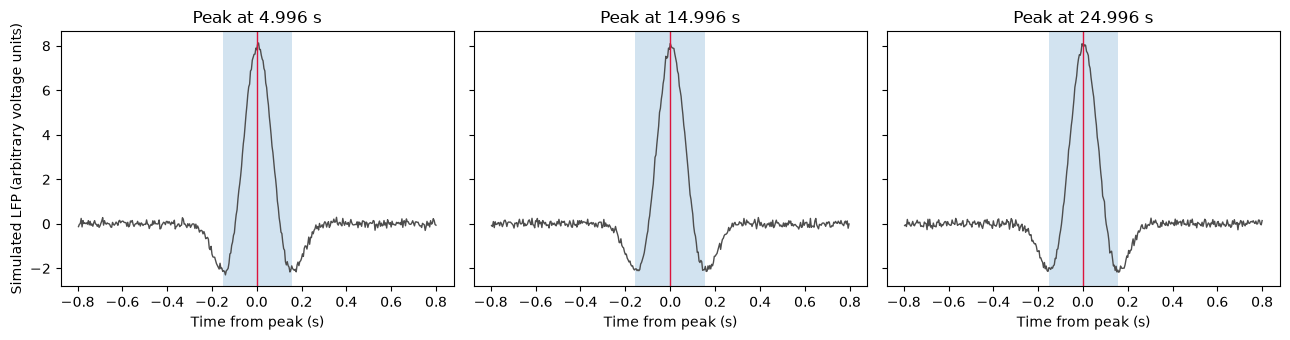

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, event in zip(axes, events.itertuples()):
    window = np.abs(sample_times - event.peaks) < 0.8
    ax.plot(sample_times[window] - event.peaks, trace[window], color="0.3", lw=1)
    ax.axvspan(event.start - event.peaks, event.stop - event.peaks, alpha=0.2)
    ax.axvline(0, color="crimson", lw=1)
    ax.set(title=f"Peak at {event.peaks:.3f} s", xlabel="Time from peak (s)")
axes[0].set_ylabel("Simulated LFP (arbitrary voltage units)")
fig.tight_layout()
plt.show()

### Visual guide: which thresholds must a wave pass?

The figures below reuse `detection_options`, so changing the named inputs above
updates the threshold lines and acceptance map when these cells are rerun.
The example waveforms and firing responses are **illustrations**, not additional
recorded events. The schematic waveforms already use standardized filtered-LFP
units; the raw artifact checks use a different standardization, shown separately.

Let **P** be the positive peak, **T** the final trough (a signed z score), and
**S** the initial trough. The detector first requires **either route A or route B**:

| Route | Peak condition | Final-trough condition | Default interpretation |
|---|---|---|---|
| A: high peak, shallow trough allowed | `P > high_peak_threshold` | `T <= -low_trough_threshold` | `P > 3` and `T <= 0` |
| B: lower peak, deeper trough required | `P >= low_peak_threshold` | `T < -high_trough_threshold` | `P >= 1` and `T < -1.5` |

**Every wave must also pass all of these:**

- `P - T > threshold` (default **3 z units**); this is a vertical difference,
  not a threshold on P alone.
- `P > S`; there is no separate amplitude threshold for the initial trough.
- `min_duration <= stop - start <= max_duration` (default **0.15–0.65 s**).
- The complete wave must lie within a usable detection segment, outside
  `edge_buffer` (default **1 s**) at each segment edge.

Trough inputs are **positive magnitudes**. Thus `high_trough_threshold=1.5` draws
a horizontal line at **−1.5**, not +1.5. Thresholds decide whether a wave qualifies;
the start and stop remain the neighboring troughs, found from derivative zero crossings.

**Four matching waveform examples (at the defaults):** A passes route A and B
passes route B. C passes route B, but its total excursion is only **2.7 z**, below
the required **>3 z**, so it is rejected. D fails both peak/trough routes and
also has an insufficient **2.7 z** excursion. C and D are rejected examples,
rather than additional acceptance routes. Each panel reports its individual
gate results and uses the same peak/trough values as its labeled map point.


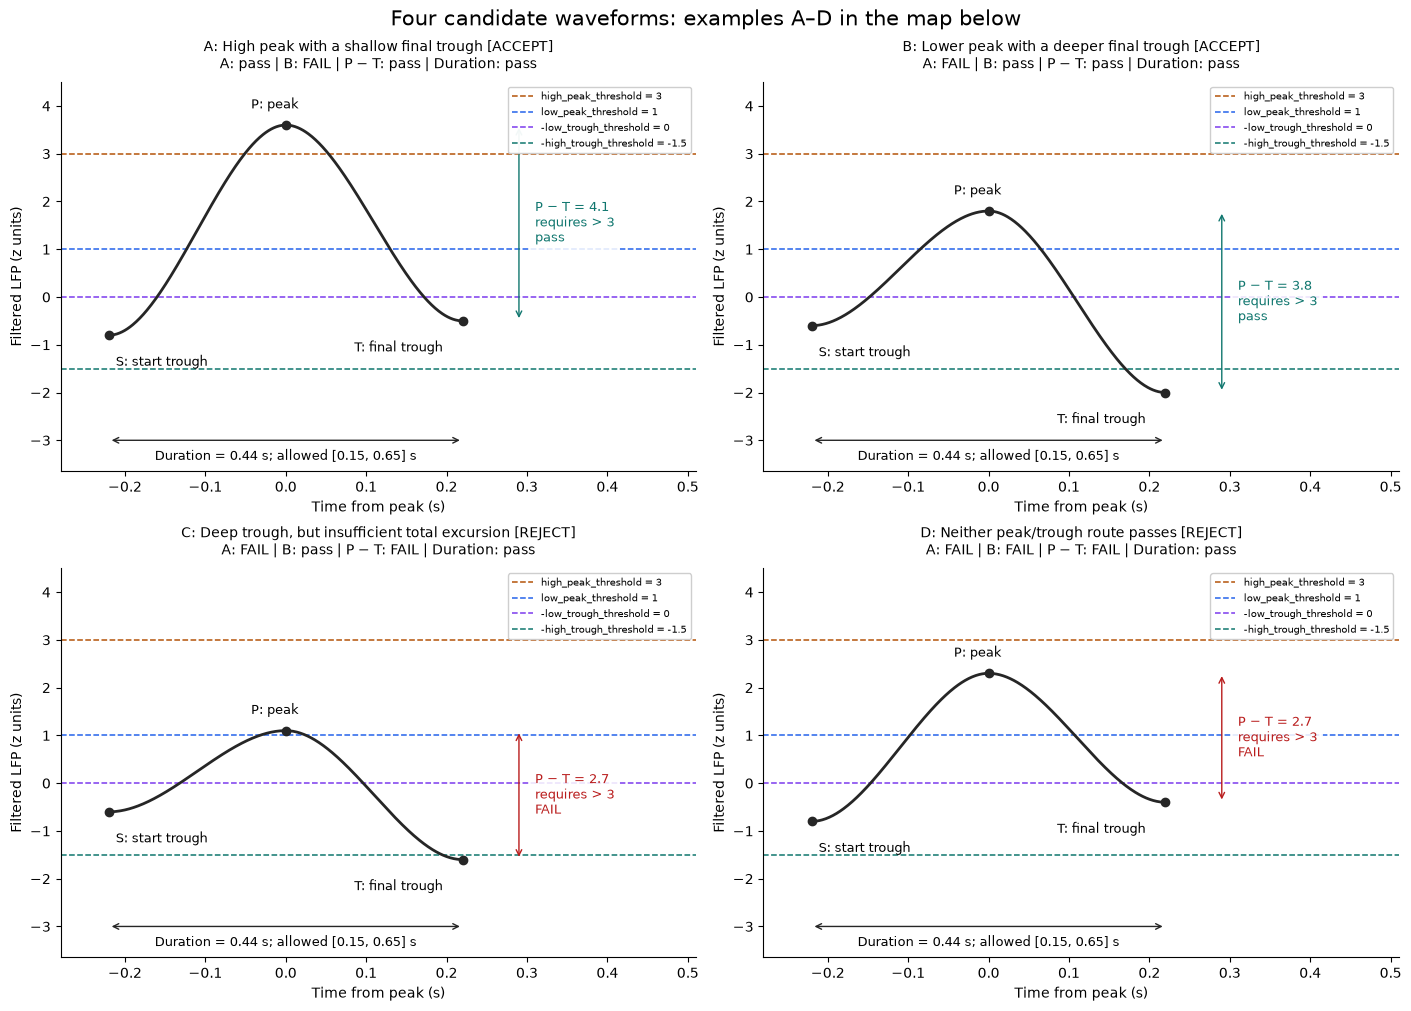

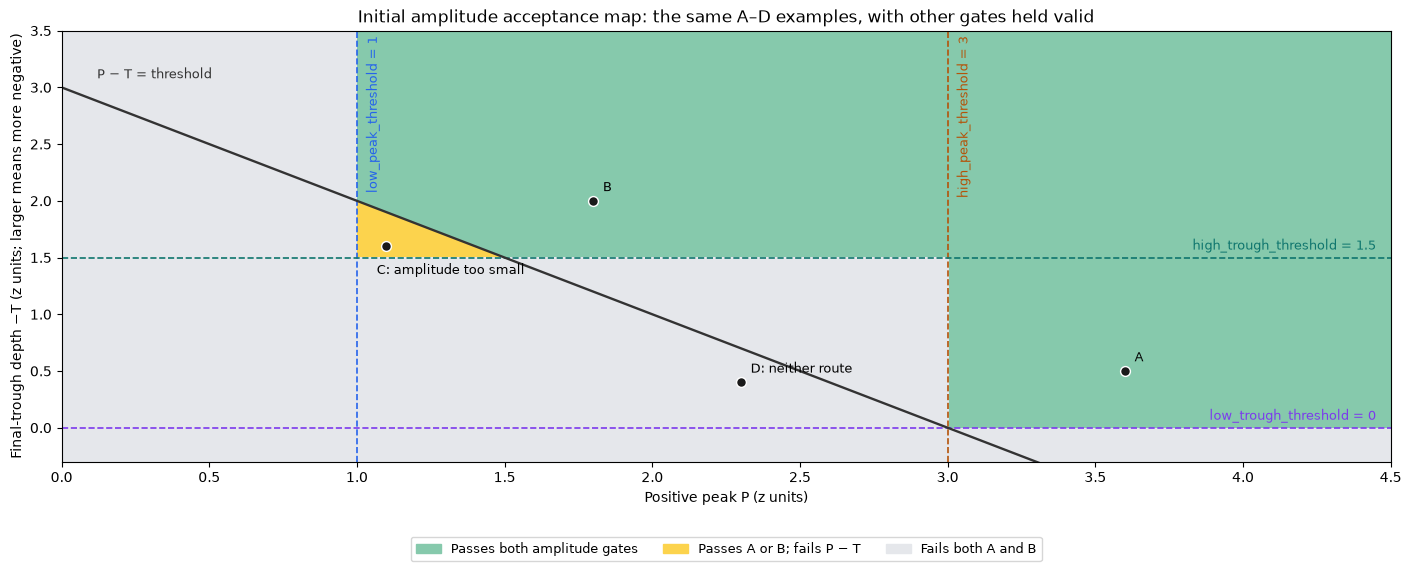

In [5]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage
from scipy.interpolate import CubicHermiteSpline

lp = detection_options["low_peak_threshold"]
hp = detection_options["high_peak_threshold"]
lt = detection_options["low_trough_threshold"]
ht = detection_options["high_trough_threshold"]
amplitude_floor = detection_options["threshold"]
minimum_duration = detection_options["min_duration"]
maximum_duration = detection_options["max_duration"]

colors = {
    "high_peak": "#b45309",
    "low_peak": "#2563eb",
    "low_trough": "#7c3aed",
    "high_trough": "#0f766e",
}
schematic_examples = [
    ("A", "High peak with a shallow final trough", -0.8, 3.6, -0.5),
    ("B", "Lower peak with a deeper final trough", -0.6, 1.8, -2.0),
    ("C", "Deep trough, but insufficient total excursion", -0.6, 1.1, -1.6),
    ("D", "Neither peak/trough route passes", -0.8, 2.3, -0.4),
]
fig, waveform_axes = plt.subplots(2, 2, figsize=(14, 10), layout="constrained")
for ax, (label, title, initial, peak, trough) in zip(
    waveform_axes.flat, schematic_examples
):
    knots = np.array([-0.22, 0.0, 0.22])
    times = np.linspace(knots[0], knots[-1], 400)
    curve = CubicHermiteSpline(knots, [initial, peak, trough], [0, 0, 0])(times)
    passes_a = peak > hp and trough <= -lt
    passes_b = peak >= lp and trough < -ht
    passes_amplitude = peak - trough > amplitude_floor
    passes_duration = minimum_duration <= knots[-1] - knots[0] <= maximum_duration
    accepted = (
        (passes_a or passes_b)
        and passes_amplitude
        and passes_duration
        and peak > initial
    )
    verdict = "ACCEPT" if accepted else "REJECT"
    status = lambda passed: "pass" if passed else "FAIL"
    checks = (
        f"A: {status(passes_a)} | B: {status(passes_b)} | "
        f"P − T: {status(passes_amplitude)} | Duration: {status(passes_duration)}"
    )
    for level, color, name in [
        (hp, colors["high_peak"], "high_peak_threshold"),
        (lp, colors["low_peak"], "low_peak_threshold"),
        (-lt, colors["low_trough"], "-low_trough_threshold"),
        (-ht, colors["high_trough"], "-high_trough_threshold"),
    ]:
        ax.axhline(
            level, color=color, ls="--", lw=1.1, label=f"{name} = {level + 0.0:g}"
        )
    ax.plot(times, curve, color="0.15", lw=2)
    ax.scatter(knots, [initial, peak, trough], color="0.15", zorder=4)
    ax.annotate(
        "S: start trough",
        (knots[0], initial),
        xytext=(5, -22),
        textcoords="offset points",
        fontsize=9,
    )
    ax.annotate(
        "P: peak", (0, peak), xytext=(-25, 12), textcoords="offset points", fontsize=9
    )
    ax.annotate(
        "T: final trough",
        (knots[-1], trough),
        xytext=(-78, -22),
        textcoords="offset points",
        fontsize=9,
    )
    decision_color = "#0f766e" if passes_amplitude else "#b91c1c"
    ax.annotate(
        "",
        (0.29, peak),
        (0.29, trough),
        arrowprops={"arrowstyle": "<->", "color": decision_color},
    )
    ax.text(
        0.31,
        (peak + trough) / 2,
        f"P − T = {peak - trough:.1f}\nrequires > {amplitude_floor:g}\n{status(passes_amplitude)}",
        fontsize=9,
        va="center",
        color=decision_color,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85},
    )
    ax.annotate(
        "",
        (knots[0], -3.0),
        (knots[-1], -3.0),
        arrowprops={"arrowstyle": "<->", "color": "0.15"},
    )
    ax.text(
        0,
        -3.18,
        f"Duration = 0.44 s; allowed [{minimum_duration:g}, {maximum_duration:g}] s",
        ha="center",
        va="top",
        fontsize=9,
    )
    ax.set(
        xlim=(-0.28, 0.51),
        ylim=(-3.65, max(4.5, hp + 1)),
        xlabel="Time from peak (s)",
        ylabel="Filtered LFP (z units)",
    )
    ax.set_title(f"{label}: {title} [{verdict}]\n{checks}", fontsize=10, pad=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper right", fontsize=7.5, framealpha=0.95)
fig.suptitle("Four candidate waveforms: examples A–D in the map below", fontsize=15)
plt.show()

fig, ax = plt.subplots(figsize=(14, 5.6), layout="constrained")
peak_axis = np.linspace(0, max(4.5, hp + 1), 700)
depth_axis = np.linspace(-0.3, max(3.5, ht + 1), 500)
peak_grid, depth_grid = np.meshgrid(peak_axis, depth_axis)
route_a = (peak_grid > hp) & (depth_grid >= lt)
route_b = (peak_grid >= lp) & (depth_grid > ht)
amplitude_pass = peak_grid + depth_grid > amplitude_floor
classes = np.where(
    (route_a | route_b) & amplitude_pass, 2, np.where(route_a | route_b, 1, 0)
)
ax.pcolormesh(
    peak_axis,
    depth_axis,
    classes,
    cmap=ListedColormap(["#e5e7eb", "#fcd34d", "#86c9ac"]),
    vmin=0,
    vmax=2,
    shading="nearest",
    rasterized=True,
)
for level, color, label in [
    (lp, colors["low_peak"], "low_peak_threshold"),
    (hp, colors["high_peak"], "high_peak_threshold"),
]:
    ax.axvline(level, color=color, ls="--", lw=1.2)
    ax.text(
        level + 0.03,
        depth_axis[-1] - 0.05,
        f"{label} = {level:g}",
        color=color,
        rotation=90,
        va="top",
        fontsize=9,
    )
for level, color, label in [
    (lt, colors["low_trough"], "low_trough_threshold"),
    (ht, colors["high_trough"], "high_trough_threshold"),
]:
    ax.axhline(level, color=color, ls="--", lw=1.2)
    ax.text(
        peak_axis[-1] - 0.05,
        level + 0.07,
        f"{label} = {level:g}",
        color=color,
        ha="right",
        fontsize=9,
    )
ax.plot(peak_axis, amplitude_floor - peak_axis, color="0.2", lw=1.7)
ax.text(0.12, amplitude_floor + 0.08, "P − T = threshold", color="0.2", fontsize=9)
map_labels = {
    "A": "A",
    "B": "B",
    "C": "C: amplitude too small",
    "D": "D: neither route",
}
for label, title, initial, peak, trough in schematic_examples:
    depth = -trough  # Use exactly the same values as the waveform panels.
    ax.scatter(peak, depth, color="0.1", edgecolors="white", s=50, zorder=5)
    offset = (-7, -20) if label == "C" else (7, 7)
    ax.annotate(
        map_labels[label],
        (peak, depth),
        xytext=offset,
        textcoords="offset points",
        fontsize=9,
    )
ax.set(
    xlim=(peak_axis[0], peak_axis[-1]),
    ylim=(depth_axis[0], depth_axis[-1]),
    xlabel="Positive peak P (z units)",
    ylabel="Final-trough depth −T (z units; larger means more negative)",
    title="Initial amplitude acceptance map: the same A–D examples, with other gates held valid",
)
ax.legend(
    handles=[
        Patch(color="#86c9ac", label="Passes both amplitude gates"),
        Patch(color="#fcd34d", label="Passes A or B; fails P − T"),
        Patch(color="#e5e7eb", label="Fails both A and B"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=3,
    fontsize=9,
)
plt.show()

**Reading the map:** green candidates pass the initial amplitude tests. Yellow
candidates have a qualifying peak/trough combination but insufficient total
peak-to-trough amplitude. Gray candidates fail both routes. The plots shade
regions for readability; the table above gives the exact strict/inclusive rules
at each boundary. The map shows the initial `threshold`, before firing verification
can raise the amplitude cutoff.

### Before morphology: EMG and artifact thresholds

These thresholds have different units and purposes from the four filtered-LFP
thresholds above. The following schematics use the detector's default values.

| Gate | Default | What it does |
|---|---|---|
| `emg_threshold` | EMG **< 0.6**, continuously for **at least 1 s** | Keeps low-EMG periods inside the requested/NREM epochs; EMG keeps its input units. Set `np.inf` to disable. |
| `reject_artifacts` amplitude check | **abs(raw z) > 6** | Removes the affected raw samples with **0.5 s** padding on both sides. |
| `reject_artifacts` difference check | **abs(diff(raw z)) > 10** | Removes fast jumps with **0.1 s** padding on both sides. This is a difference of raw-signal z scores, **not** a separately z-scored derivative. |
| `edge_buffer` | **1 s** | Keeps full waves away from the start/end of each filtered usable segment, including new edges created by artifact removal. |

Artifact cutoffs/padding and the minimum low-EMG duration are fixed implementation
defaults; `reject_artifacts=False` disables both artifact checks. NREM restriction,
`detection_epochs`, and `ignore_intervals` select time intervals rather than SD
levels. `filter_band` and `passband` are frequency settings, not amplitude thresholds.

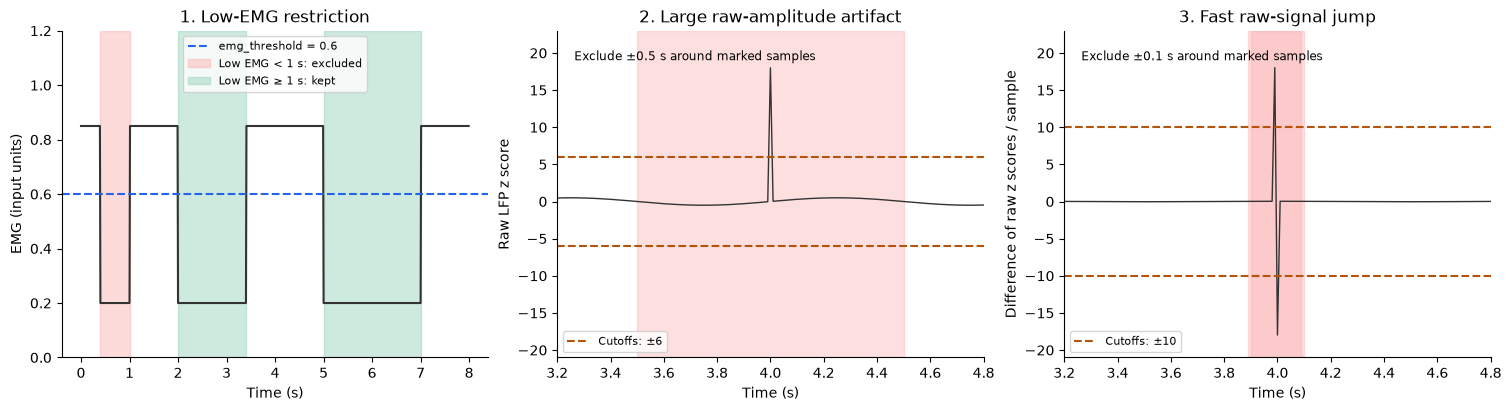

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
illustration_time = np.arange(0, 8, 0.01)
emg = np.full(illustration_time.size, 0.85)
for start, stop in [(0.4, 1.0), (2.0, 3.4), (5.0, 7.0)]:
    emg[(illustration_time >= start) & (illustration_time <= stop)] = 0.2
ax = axes[0]
ax.plot(illustration_time, emg, color="0.2")
ax.axhline(0.6, color="#2563eb", ls="--", label="emg_threshold = 0.6")
ax.axvspan(0.4, 1.0, color="#fca5a5", alpha=0.4, label="Low EMG < 1 s: excluded")
ax.axvspan(2.0, 3.4, color="#86c9ac", alpha=0.4, label="Low EMG ≥ 1 s: kept")
ax.axvspan(5.0, 7.0, color="#86c9ac", alpha=0.4)
ax.set(
    xlabel="Time (s)",
    ylabel="EMG (input units)",
    ylim=(0, 1.2),
    title="1. Low-EMG restriction",
)
ax.legend(loc="upper center", fontsize=8)

raw_z = 0.5 * np.sin(2 * np.pi * illustration_time)
artifact_index = np.argmin(np.abs(illustration_time - 4))
raw_z[artifact_index] = 18  # Schematic standardized raw signal.
raw_difference = np.r_[np.diff(raw_z), 0.0]
for ax, values, cutoff, padding, title, ylabel in [
    (axes[1], raw_z, 6, 0.5, "2. Large raw-amplitude artifact", "Raw LFP z score"),
    (
        axes[2],
        raw_difference,
        10,
        0.1,
        "3. Fast raw-signal jump",
        "Difference of raw z scores / sample",
    ),
]:
    ax.plot(illustration_time, values, color="0.2", lw=1)
    ax.axhline(cutoff, color="#b45309", ls="--", label=f"Cutoffs: ±{cutoff:g}")
    ax.axhline(-cutoff, color="#b45309", ls="--")
    marked = np.flatnonzero(np.abs(values) > cutoff)
    for sample in marked:
        ax.axvspan(
            illustration_time[sample] - padding,
            illustration_time[sample] + padding,
            color="#fca5a5",
            alpha=0.35,
        )
    ax.set(
        xlim=(3.2, 4.8), ylim=(-21, 23), xlabel="Time (s)", ylabel=ylabel, title=title
    )
    ax.text(
        0.04,
        0.94,
        f"Exclude ±{padding:g} s around marked samples",
        transform=ax.transAxes,
        va="top",
        fontsize=8.5,
    )
    ax.legend(loc="lower left", fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

### After morphology: default firing verification may raise `threshold`

With `verify_firing=True` (the default), the detector pools cortical spikes, makes
a **±0.5 s** PETH for each candidate in **10 ms** bins, smooths it with a Gaussian
of **one-bin sigma**, and z-scores each candidate's PETH across time. It averages
that standardized response within **±50 ms** of the delta peak. This firing-response
z score is distinct from both raw-LFP and filtered-LFP z scores.

Candidates are sorted by decreasing `amplitude = P - T`. A moving mean over up to
**100 candidates** must be **≤ −0.5** to support a cutoff. The lowest amplitude at
which that smoothed response meets the criterion becomes the proposed cutoff;
the effective cutoff is `max(threshold, proposed_cutoff)`. Events must exceed it
strictly. The peak/trough thresholds and trough-based boundaries stay unchanged.
The figure below illustrates this heuristic; its firing data are simulated.

The PETH window, bin size, smoothing, averaging window, moving-mean width, and
−0.5 response criterion are fixed heuristic settings. This is not a significance
test. Missing cortical cells or unsuccessful verification triggers a warning,
retains the initial LFP detections, and records `firing_verified=False`.

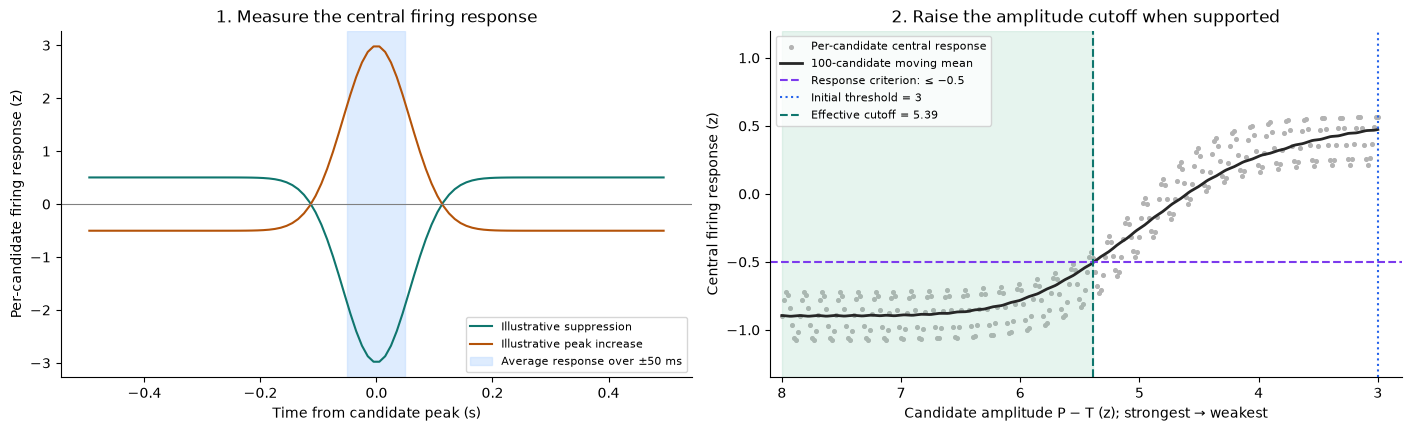

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), layout="constrained")
peth_edges = np.linspace(-0.5, 0.5, 101)
peth_centers = (peth_edges[:-1] + peth_edges[1:]) / 2
for sign, color, label in [
    (-1, "#0f766e", "Illustrative suppression"),
    (1, "#b45309", "Illustrative peak increase"),
]:
    counts = 10 + sign * 7 * np.exp(-((peth_centers / 0.08) ** 2))
    smooth = ndimage.gaussian_filter1d(counts, 1.0)
    standardized = (smooth - smooth.mean()) / smooth.std(ddof=1)
    axes[0].plot(peth_centers, standardized, color=color, label=label)
axes[0].axvspan(
    -0.05, 0.05, color="#bfdbfe", alpha=0.5, label="Average response over ±50 ms"
)
axes[0].axhline(0, color="0.5", lw=0.8)
axes[0].set(
    xlabel="Time from candidate peak (s)",
    ylabel="Per-candidate firing response (z)",
    title="1. Measure the central firing response",
)
axes[0].legend(loc="lower right", fontsize=8)

illustrative_amplitudes = np.linspace(
    8, 3, 300
)  # Same descending order as the detector.
illustrative_responses = (
    -0.9
    + 1.3 / (1 + np.exp((illustrative_amplitudes - 5) * 3))
    + 0.18 * np.sin(np.arange(300) * 0.7)
)
response_mean = ndimage.uniform_filter1d(
    illustrative_responses, size=100, mode="nearest"
)
supported = np.flatnonzero(response_mean <= -0.5)
proposed_cutoff = illustrative_amplitudes[supported[-1]]
effective_cutoff = max(amplitude_floor, proposed_cutoff)
ax = axes[1]
ax.scatter(
    illustrative_amplitudes,
    illustrative_responses,
    color="0.7",
    s=7,
    label="Per-candidate central response",
)
ax.plot(
    illustrative_amplitudes,
    response_mean,
    color="0.15",
    lw=2,
    label="100-candidate moving mean",
)
ax.axhline(-0.5, color="#7c3aed", ls="--", label="Response criterion: ≤ −0.5")
ax.axvline(
    amplitude_floor,
    color="#2563eb",
    ls=":",
    label=f"Initial threshold = {amplitude_floor:g}",
)
ax.axvline(
    effective_cutoff,
    color="#0f766e",
    ls="--",
    label=f"Effective cutoff = {effective_cutoff:.2f}",
)
ax.axvspan(effective_cutoff, illustrative_amplitudes.max(), color="#86c9ac", alpha=0.2)
ax.set(
    xlim=(8.1, min(2.8, amplitude_floor - 0.2)),
    ylim=(-1.35, 1.2),
    xlabel="Candidate amplitude P − T (z); strongest → weakest",
    ylabel="Central firing response (z)",
    title="2. Raise the amplitude cutoff when supported",
)
ax.legend(loc="upper left", fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

**What to tune:** use `threshold` to change the required total excursion, the four
named peak/trough inputs to change the allowed wave shape, and `min_duration` /
`max_duration` to change the allowed timescale. Use `emg_threshold` for the EMG
restriction, `edge_buffer` for filtering edges, `reject_artifacts` to enable/disable
artifact rejection, and `verify_firing` to enable/disable firing refinement.
The effective post-verification amplitude cutoff is saved as
`events.attrs["detectorinfo"]["threshold"]`; the requested initial settings are in
`events.attrs["detectorinfo"]["detectionparms"]`.

## Optional high-gamma confirmation

A large slow voltage deflection can resemble a delta wave while the local network
is still active. High-gamma power provides a complementary measure: a drop in this
power can support the interpretation that the positive delta peak marks a cortical
DOWN state with reduced population firing.

[Levenstein et al. (2019), *Slow wave detection*](https://pmc.ncbi.nlm.nih.gov/articles/PMC6554409/#Sec10)
combined delta peaks with suppression of **100–400 Hz** power, smoothed over
**80 ms** and normalized within a **20 s** neighborhood. Their thresholds were
calibrated against spikes and they required overlapping delta and gamma events.

Our optional check adapts that idea to the existing detector. It bandpasses a
user-selected gamma voltage channel, smooths its squared voltage, and computes
local mean/SD z scores. An event survives only if a continuous interval at or below
`gamma_threshold` contains the **positive delta peak** and occupies at least
`gamma_min_duration` **within the original trough-to-trough event**. Accepted event
boundaries and delta amplitudes stay unchanged. This is a confirmation step,
not a reproduction of the paper's full detector: normalization is conventional
mean/SD, and the exposed threshold is not automatically calibrated from spikes.

The synthetic example has three equally valid delta waveforms. Gamma is suppressed
at 5 and 25 s but increases at 15 s. The gamma check should reject only the middle
wave. We use **1250 Hz** sampling because the default 400 Hz upper cutoff needs
`fs > 800`; the earlier 250 Hz example cannot support that band.


In [8]:
from scipy import ndimage, signal

gamma_demo_fs = 1250
gamma_demo_time = np.arange(0, 30, 1 / gamma_demo_fs)
gamma_demo_rng = np.random.default_rng(818)
gamma_demo_delta = gamma_demo_rng.normal(0, 0.1, gamma_demo_time.size)
for peak in (5, 15, 25):
    relative = gamma_demo_time - peak
    gamma_demo_delta += 8 * np.cos(2 * np.pi * 2.5 * relative) * np.exp(-(relative / 0.15) ** 2)

gamma_demo_sos = signal.butter(
    4, (100, 400), btype="bandpass", fs=gamma_demo_fs, output="sos"
)
gamma_demo_voltage = signal.sosfiltfilt(
    gamma_demo_sos, gamma_demo_rng.normal(size=gamma_demo_time.size)
)
gamma_demo_envelope = np.ones(gamma_demo_time.size)
for peak in (5, 25):
    gamma_demo_envelope *= 1 - 0.99 * np.exp(-((gamma_demo_time - peak) / 0.22) ** 8)
gamma_demo_envelope += 4 * np.exp(-((gamma_demo_time - 15) / 0.22) ** 8)
gamma_demo_voltage *= gamma_demo_envelope

gamma_options = dict(
    gamma_band=(100.0, 400.0),
    gamma_threshold=0.0,       # at or below the local mean power
    gamma_smoothing=0.08,     # seconds
    gamma_baseline=20.0,      # seconds
    gamma_min_duration=0.04,  # seconds of continuous suppression containing the peak
)
gamma_demo_options = dict(
    lfp=gamma_demo_delta, timestamps=gamma_demo_time, fs=gamma_demo_fs,
    nrem_restrict=False, emg_threshold=np.inf, reject_artifacts=False,
    verify_firing=False, save_mat=False, **detection_options,
)
gamma_demo_candidates = detect_delta_waves(**gamma_demo_options)
gamma_demo_confirmed = detect_delta_waves(
    **gamma_demo_options, gamma_lfp=gamma_demo_voltage, **gamma_options
)
assert len(gamma_demo_candidates) == 3
np.testing.assert_allclose(gamma_demo_confirmed.peaks, [5, 25], atol=0.02)
print(f"Delta morphology: {len(gamma_demo_candidates)} events; with gamma confirmation: {len(gamma_demo_confirmed)}")
display(gamma_demo_confirmed[["start", "peaks", "stop", "amplitude"]])


Delta morphology: 3 events; with gamma confirmation: 2


,start,peaks,stop,amplitude
0,4.8456,4.9992,5.1528,12.876074
1,24.8456,24.9992,25.1528,12.871615


### Follow the decision from voltage to local power

Each column follows the same candidate through three views. The shaded strip is
the delta event's original duration; the dashed vertical line is its positive
peak. The bottom row shows the signal used for the gamma decision. Blue shading
marks power below the threshold, and the black bar marks the required 40 ms
duration centered on the peak for reference. Suppression may be asymmetric; the
actual rule requires the peak to lie anywhere inside a sufficiently long interval.


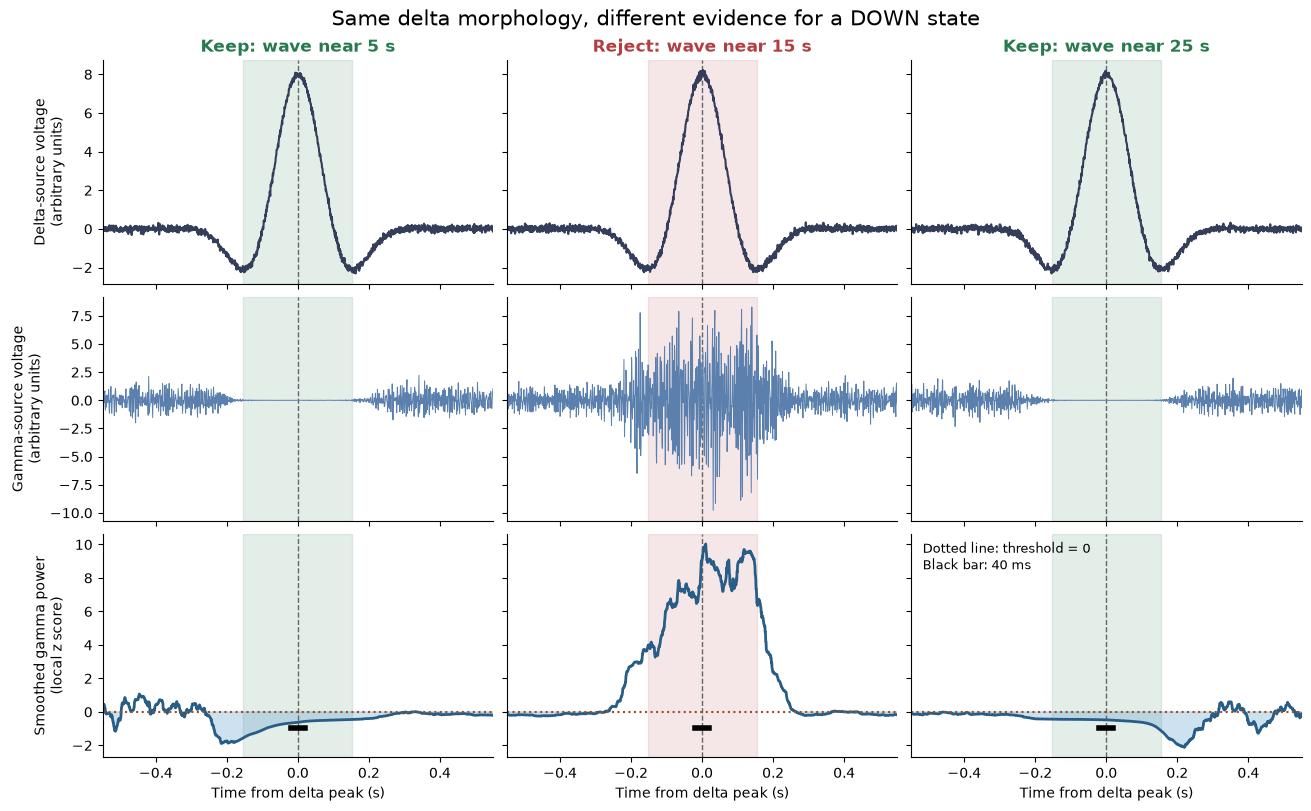

In [9]:
# Reproduce the documented power calculation for plotting, without private APIs.
gamma_demo_filtered = signal.sosfiltfilt(gamma_demo_sos, gamma_demo_voltage)
gamma_demo_smooth_samples = 2 * int(round(gamma_options["gamma_smoothing"] * gamma_demo_fs / 2)) + 1
gamma_demo_baseline_samples = 2 * int(round(gamma_options["gamma_baseline"] * gamma_demo_fs / 2)) + 1
gamma_demo_power = ndimage.uniform_filter1d(
    gamma_demo_filtered**2, gamma_demo_smooth_samples, mode="reflect"
)
gamma_demo_power -= np.median(gamma_demo_power)
gamma_demo_mean = ndimage.uniform_filter1d(gamma_demo_power, gamma_demo_baseline_samples, mode="reflect")
gamma_demo_sd = np.sqrt(np.maximum(
    ndimage.uniform_filter1d(gamma_demo_power**2, gamma_demo_baseline_samples, mode="reflect")
    - gamma_demo_mean**2, 0,
))
gamma_demo_z = np.divide(
    gamma_demo_power - gamma_demo_mean, gamma_demo_sd,
    out=np.full_like(gamma_demo_power, np.nan), where=gamma_demo_sd > 0,
)

gamma_fig, gamma_axes = plt.subplots(3, 3, figsize=(13, 8), sharex="col", sharey="row", layout="constrained")
for column, (_, event) in enumerate(gamma_demo_candidates.iterrows()):
    peak = event.peaks
    view = np.abs(gamma_demo_time - peak) <= 0.55
    relative = gamma_demo_time[view] - peak
    accepted = np.any(np.isclose(gamma_demo_confirmed.peaks, peak, atol=0.02))
    color = "#28794f" if accepted else "#b13f42"
    for ax in gamma_axes[:, column]:
        ax.axvspan(event.start - peak, event.stop - peak, color=color, alpha=0.12)
        ax.axvline(0, color="0.4", ls="--", lw=1)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_xlim(-0.55, 0.55)
    gamma_axes[0, column].plot(relative, gamma_demo_delta[view], color="#343d59", lw=1.5)
    gamma_axes[0, column].set_title(
        f"{'Keep' if accepted else 'Reject'}: wave near {round(peak)} s", color=color, weight="bold"
    )
    gamma_axes[1, column].plot(relative, gamma_demo_voltage[view], color="#5b80ad", lw=0.7)
    gamma_axes[2, column].plot(relative, gamma_demo_z[view], color="#285d87", lw=2)
    gamma_axes[2, column].axhline(gamma_options["gamma_threshold"], color="#9b4f21", ls=":", lw=1.5)
    gamma_axes[2, column].fill_between(
        relative, gamma_demo_z[view], gamma_options["gamma_threshold"],
        where=gamma_demo_z[view] <= gamma_options["gamma_threshold"],
        color="#5b9dcc", alpha=0.3,
    )
    half_duration = gamma_options["gamma_min_duration"] / 2
    gamma_axes[2, column].plot([-half_duration, half_duration], [-0.95, -0.95], color="black", lw=4)
    gamma_axes[2, column].set_xlabel("Time from delta peak (s)")
gamma_axes[0, 0].set_ylabel("Delta-source voltage\n(arbitrary units)")
gamma_axes[1, 0].set_ylabel("Gamma-source voltage\n(arbitrary units)")
gamma_axes[2, 0].set_ylabel("Smoothed gamma power\n(local z score)")
gamma_axes[2, 2].text(0.03, 0.97, "Dotted line: threshold = 0\nBlack bar: 40 ms", transform=gamma_axes[2, 2].transAxes, va="top", fontsize=9)
gamma_fig.suptitle("Same delta morphology, different evidence for a DOWN state", fontsize=15)
plt.show()


### Choose the channel and tune the confirmation

For a session, pass **`gamma_channel=<zero-indexed cortical channel>`**. It may be
the delta channel or a separate channel from the same cortical population. The
detector reads a view of that channel from the existing LFP memmap. For arrays,
use **`gamma_lfp=voltage`** with exactly the same sample count, timestamps and
sampling rate as `lfp`; there is no implicit resampling. An optional `gamma_channel`
then serves only as an array-channel label. Supply raw voltage, not power values.

| Input | Default | Effect |
| --- | --- | --- |
| `gamma_band` | `(100, 400)` Hz | Frequencies used as the activity proxy; both cutoffs must lie below Nyquist. |
| `gamma_threshold` | `0.0` local SD | Power must be at or below this value; negative values demand stronger suppression. |
| `gamma_smoothing` | `0.08` s | Power averaging window; larger windows blur brief transitions. |
| `gamma_baseline` | `20.0` s | Local normalization window; must exceed the smoothing window. |
| `gamma_min_duration` | `0.04` s | Continuous suppression within the event, containing its positive peak. |

The default threshold is an exposed starting point, **not a cutoff established by
the paper**. Check wave-triggered gamma and, when available, spikes in your own
recording before choosing it. A channel with gamma power that tracks cortical
firing is more useful than an arbitrary channel; line noise, muscle activity and
channel location can affect this proxy. Stronger suppression requirements improve
selectivity but may discard real waves with weak gamma modulation.

Both channels respect the same NREM/EMG and interval restrictions. NaNs, timestamp
gaps and rejected artifacts split the data; filtering and local normalization never
join across them. Missing/constant gamma voltage cannot confirm a wave. Local
windows reflect at segment edges, with the configured edge buffer excluded.

Gamma confirmation runs **before** the independent `verify_firing` step, whose
default remains `True`. Gamma does not replace the missing-cortical-cells warning.
Here we disabled firing verification because the simulation has no spike trains.
The metadata records all gamma settings, the source channel in both numbering
conventions, and `gamma_rejected` (the count removed before firing refinement).
No gamma source means no gamma filtering and the original behavior.


## 3. Restrict detection and exclude an interval

`detection_epochs` and `ignore_intervals` accept `(n_intervals, 2)` arrays in
seconds or `nelpy.EpochArray` objects. The following example keeps the first and
last recording windows, then excludes the last wave. Excluded samples and
recording gaps are never bridged by a detected event.

In [10]:
restricted = detect_delta_waves(
    **array_options,
    detection_epochs=[[2, 8], [22, 28]],
    ignore_intervals=[[24.9, 25.1]],
    save_mat=False,
)
display(restricted[["start", "peaks", "stop", "amplitude"]])
np.testing.assert_allclose(restricted.peaks, [5.0], atol=0.02)
display(restricted.attrs["detectorinfo"]["detectionintervals"])

,start,peaks,stop,amplitude
0,4.844,4.996,5.152,12.87939


array([[ 3.   ,  7.   ],
       [23.   , 23.896],
       [26.1  , 27.   ]])

## 4. Event fields and metadata


Each row contains `start`, `stop`, `timestamps`, `peaks`, `amplitude`,
`amplitudeUnits`, `values`, `eventID`, `eventIDlabels`, `eventIDbinary`, `center`,
and `duration`. Times are seconds; amplitude is the peak-to-final-trough
difference in z units. The `values` tuple holds standardized initial trough,
peak, and final trough values, also exposed as `start_value`, `peak_value`, and
`stop_value` columns. All events have ID 1 and label `delta`.

Shared metadata lives in `events.attrs["detectorinfo"]`, including the usable
detection intervals, parameters, effective amplitude threshold, UTC detection
date, and detection channel in both indexing conventions. The saved MATLAB
struct follows the [CellExplorer events format](https://cellexplorer.org/datastructure/data-structure-and-format/#events),
including `(n_events, 2)` timestamps, column vectors for event measurements, and
an `(n_events, 3)` values array. Zero-event and one-event exports preserve these shapes.

In [11]:
display(events.head())
display(events.attrs["detectorinfo"])

,start,stop,peaks,amplitude,center,duration,start_value,peak_value,stop_value,timestamps,values,amplitudeUnits,eventID,eventIDlabels,eventIDbinary
0,4.844,5.152,4.996,12.853640,4.998,0.308,-3.305979,9.579129,-3.274511,"(4.844, 5.152)","(-3.305978559103749, 9.579129400871798, -3.274...",zscore,1,delta,False
1,14.840,15.152,14.996,12.809630,14.996,0.312,-3.237116,9.550003,-3.259627,"(14.84, 15.152000000000001)","(-3.237115547648009, 9.550003020049603, -3.259...",zscore,1,delta,False
2,24.844,25.152,24.996,12.841885,24.998,0.308,-3.217037,9.587129,-3.254756,"(24.844, 25.152)","(-3.2170372924046107, 9.587129134656248, -3.25...",zscore,1,delta,False


{'detectorname': 'neuro_py.detectors.detect_delta_waves',
 'detectiondate': '2026-10-19T14:31:11.444120+00:00',
 'detectionintervals': array([[ 1.   , 28.996]]),
 'detectionparms': {'channel': [],
  'threshold': 3.0,
  'low_peak_threshold': 1.0,
  'high_peak_threshold': 3.0,
  'low_trough_threshold': 0.0,
  'high_trough_threshold': 1.5,
  'min_duration': 0.15,
  'max_duration': 0.65,
  'filter_band': (0.5, 9.0),
  'passband': (1.0, 6.0),
  'fs': 250.0,
  'nrem_restrict': False,
  'emg_threshold': inf,
  'reject_artifacts': False,
  'edge_buffer': 1.0,
  'brain_regions': ['PFC', 'MEC', 'LEC', 'EC', 'ILA', 'PL', 'Cortex', 'CTX'],
  'verify_firing': False,
  'firing_verified': False,
  'gamma_enabled': False,
  'gamma_channel': [],
  'gamma_band': (100.0, 400.0),
  'gamma_threshold': 0.0,
  'gamma_smoothing': 0.08,
  'gamma_baseline': 20.0,
  'gamma_min_duration': 0.04,
  'gamma_rejected': 0,
  'ignore_intervals': array([], shape=(0, 2), dtype=float64)},
 'detectionchannel': [],
 'detecti

## 5. Save the default filename, customize it, and verify overwrite protection

This cell runs in a new temporary session directory each time. It exercises the
detector's default saving behavior, reads back the CellExplorer struct, and saves
a custom event name. The temporary files are removed when the cell completes.
For a real session, the same defaults produce `basename.deltaWaves.events.mat`.

In [12]:
with TemporaryDirectory(prefix="neuro_py_delta_tutorial_") as temporary:
    demo_basepath = Path(temporary) / "demo"
    demo_basepath.mkdir()

    # save_mat=True and event_name="deltaWaves" are the detector defaults.
    saved_events = detect_delta_waves(basepath=demo_basepath, **array_options)
    default_path = Path(saved_events.attrs["event_file"])
    assert default_path.name == "demo.deltaWaves.events.mat"
    saved = load_mat(default_path)["deltaWaves"]
    np.testing.assert_allclose(saved["timestamps"], events[["start", "stop"]])
    np.testing.assert_allclose(np.asarray(saved["peaks"]).ravel(), events.peaks)
    print(f"Default filename: {default_path.name}")

    custom_path = Path(
        save_delta_wave_events(events, demo_basepath, event_name="myDeltaWaves")
    )
    assert custom_path.name == "demo.myDeltaWaves.events.mat"
    print(f"Custom filename: {custom_path.name}")

    original_bytes = default_path.read_bytes()
    try:
        save_delta_wave_events(events, demo_basepath)
    except FileExistsError:
        print("Existing event file protected: FileExistsError raised as expected.")
    else:
        raise AssertionError("An existing event file should never be replaced.")
    assert default_path.read_bytes() == original_bytes

Default filename: demo.deltaWaves.events.mat
Custom filename: demo.myDeltaWaves.events.mat
Existing event file protected: FileExistsError raised as expected.


## 6. Optional: run on a CellExplorer session

Set `RUN_SESSION=True` and edit `basepath` if needed. The default session workflow
uses the `Delta` channel tag, or selects the channel with the greatest relative
1–6 Hz power among matching cortical regions. Channels tagged `Bad` are excluded.
Public `channel` arguments use **zero-based** indexing; MATLAB metadata is
converted automatically (`channel=53` is MATLAB channel 54).

The session needs `.session.mat`, `.lfp` (or `.eeg`), `.SleepState.states.mat`,
and `.EMGFromLFP.LFP.mat`. Detection is restricted to NREM and EMG below 0.6 for
at least one second. Set `nrem_restrict=False` and/or `emg_threshold=np.inf` to
disable a restriction explicitly. This run keeps the default artifact rejection.

Session detection below uses `save_mat=False` so it can be rerun safely. A separate
export cell is controlled by `SAVE_SESSION_EVENTS`. Its event name defaults to
`deltaWaves`; choose a custom name to keep an existing detection alongside it.

The session workflow uses default firing verification and loads spikes from matching cortical regions. If none are available, it warns and retains the LFP detections.

Set `session_gamma_channel` below to a zero-indexed cortical channel to use the optional gamma confirmation with `gamma_options` from the synthetic example. Its default `None` preserves the delta-only workflow. Keep saving disabled while comparing detectors; choose a distinct `session_event_name`, such as `deltaWavesGamma`, to save a comparison.

In [13]:
RUN_SESSION = True
basepath = Path(r"S:\data\HMC\HMC1\day8")
SAVE_SESSION_EVENTS = False
session_event_name = "deltaWaves_test"
# Set to a zero-indexed cortical channel to enable gamma confirmation.
session_gamma_channel = None

session_events = None
if RUN_SESSION:
    session_events = detect_delta_waves(
        basepath, **detection_options, gamma_channel=session_gamma_channel,
        **gamma_options, save_mat=False,
    )
    print(f"Detected {len(session_events)} delta waves in {basepath.name}.")
    display(session_events[["start", "peaks", "stop", "duration", "amplitude"]].head())
    display(session_events.attrs["detectorinfo"])
else:
    print("Session example skipped. Set RUN_SESSION=True to execute it.")

Detected 4267 delta waves in day8.


,start,peaks,stop,duration,amplitude
0,147.3288,147.4352,147.5608,0.2320,4.573611
1,239.1672,239.2984,239.4808,0.3136,6.354530
2,243.8168,243.9720,244.1208,0.3040,3.573012
3,248.2280,248.3384,248.5232,0.2952,4.578029
4,253.4328,253.5608,253.7760,0.3432,3.790883


{'detectorname': 'neuro_py.detectors.detect_delta_waves',
 'detectiondate': '2026-10-19T14:36:44.079849+00:00',
 'detectionintervals': array([[   75.    ,    86.    ],
        [  119.    ,   184.    ],
        [  212.    ,   256.    ],
        [  307.    ,   317.    ],
        [  332.    ,   353.    ],
        [  373.    ,   395.    ],
        [  426.    ,   461.    ],
        [  675.    ,   701.    ],
        [  738.    ,   754.    ],
        [  776.    ,   782.    ],
        [  889.    ,   895.    ],
        [  934.    ,   953.    ],
        [ 1014.    ,  1044.    ],
        [ 1108.    ,  1140.    ],
        [ 1347.    ,  1414.    ],
        [ 1438.    ,  1451.    ],
        [ 1465.    ,  1477.    ],
        [ 3199.    ,  3211.    ],
        [ 3267.    ,  3275.    ],
        [ 3308.    ,  3318.    ],
        [ 3339.    ,  3363.    ],
        [ 3442.    ,  3454.    ],
        [ 3635.    ,  3640.    ],
        [ 4792.    ,  4794.6512],
        [ 4835.172 ,  4837.    ],
        [ 5162. 

Plot the first session wave using a short slice of the memory-mapped recording.
The full multichannel LFP is not copied into memory. If no waves were detected,
the plot is skipped.

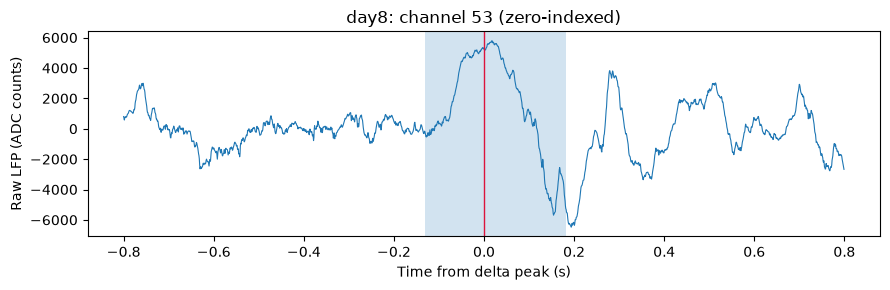

In [14]:
if RUN_SESSION and session_events is not None and not session_events.empty:
    info = session_events.attrs["detectorinfo"]
    session_fs = info["detectionparms"]["fs"]
    channel = int(info["detectionchannel"])
    metadata = load_mat(basepath / f"{basepath.name}.session.mat")["session"]
    loaded = loading.loadLFP(
        str(basepath),
        n_channels=int(metadata["extracellular"]["nChannels"]),
        frequency=session_fs,
    )
    if loaded is None:
        raise FileNotFoundError(f"No LFP recording found in {basepath}.")
    session_lfp, session_times = loaded
    event = session_events.iloc[1]
    left, right = np.searchsorted(session_times, [event.peaks - 0.8, event.peaks + 0.8])
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(
        session_times[left:right] - event.peaks,
        session_lfp[left:right, channel],
        lw=0.8,
    )
    ax.axvspan(event.start - event.peaks, event.stop - event.peaks, alpha=0.2)
    ax.axvline(0, color="crimson", lw=1)
    ax.set(
        xlabel="Time from delta peak (s)",
        ylabel="Raw LFP (ADC counts)",
        title=f"{basepath.name}: channel {channel} (zero-indexed)",
    )
    fig.tight_layout()
    plt.show()
    del session_lfp, session_times, loaded

In [15]:
if SAVE_SESSION_EVENTS:
    if session_events is None:
        raise ValueError("Run the session detection cell before saving its events.")
    destination = basepath / f"{basepath.name}.{session_event_name}.events.mat"
    if destination.exists():
        print(
            f"Kept existing file: {destination}. Choose a different session_event_name to save another run."
        )
    else:
        filename = save_delta_wave_events(
            session_events, basepath, event_name=session_event_name
        )
        print(f"Saved {filename}")
else:
    print(
        "Session export disabled. Set SAVE_SESSION_EVENTS=True to save a reviewed detection."
    )

Session export disabled. Set SAVE_SESSION_EVENTS=True to save a reviewed detection.


## Algorithm and differences from neurocode


The morphology detector follows `FindDeltaWaves.m`: subtract a fifth-order
0.5 Hz Chebyshev-II lowpass from the raw LFP, lowpass at 9 Hz, differentiate,
and lowpass the derivative at 9 Hz using order eight. Both filtering stages
use forward/backward filtering with 20 dB stopband attenuation. Upward/downward/
upward derivative zero crossings identify the initial trough, positive peak,
and final trough. Wave amplitudes use sample standard deviations pooled across
the usable segments. The initial trough must be below the peak, and waves must
last 150–650 ms. Acceptance requires either a peak above 3 SD with a nonpositive
final trough, or a peak at least 1 SD with a final trough below -1.5 SD. The
peak-to-final-trough difference must also exceed `threshold=3`.

`filter_band` controls morphology filtering; `passband` controls channel selection
only. This distinction reflects what the MATLAB code actually does.

The Python implementation uses stable second-order sections at the native
sampling rate. It filters each contiguous usable segment separately, excludes
NaNs and artifacts instead of interpolating over them, and rejects events within
`edge_buffer=1` second of segment boundaries. Artifacts use the MATLAB wrapper's
6 SD amplitude and 10 SD difference criteria, with 0.5 s and 0.1 s padding.
The difference threshold is in SD units of the raw signal, as in `CleanLFP.m`.
These choices prevent events across gaps but can exclude waves retained by MATLAB.
The Python sample clock starts at zero, consistent with other neuro_py loaders;
the MATLAB wrapper starts at `1/fs`.

Firing verification defaults to **`True`**, matching the MATLAB wrapper's
executable default. It can raise the amplitude cutoff based on cortical
population firing suppression. Set `verify_firing=False` to disable it.
Supply `spike_times` as one seconds-based array per unit. Otherwise cortical
spikes are loaded through `loading.load_spikes`. This heuristic uses 10 ms bins
over ±0.5 s, Gaussian smoothing with sigma one bin, per-event z scores averaged
over ±50 ms, and a moving mean over up to 100 amplitude-ordered events. It uses
the lowest amplitude cutoff with mean suppression ≤-0.5 and never lowers the
requested amplitude threshold. Missing spikes or absent suppression produce a
warning and retain the LFP detections; metadata records verification as unsuccessful.
No interactive debugger or channel picker runs.